In [82]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder,StandardScaler

from sklearn.metrics import confusion_matrix,accuracy_score,classification_report

In [83]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans

In [84]:
student_features = pd.read_csv('data/processed/student_features_advanced.csv')

In [85]:
student_features.head()

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,...,engagement_span_days,activity_density,click_std,daily_click_mean,click_cv,unique_sites_visited,clicks_early,clicks_mid,clicks_late,early_engagement_ratio
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,...,258.0,0.155039,27.883411,23.050000,1.209692,55.0,528.0,182.0,212.0,0.572668
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,...,249.0,0.321285,20.565729,17.612500,1.167678,84.0,660.0,443.0,306.0,0.468417
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,...,22.0,0.545455,17.447758,21.666667,0.805281,22.0,260.0,0.0,0.0,1.000000
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,...,274.0,0.448905,14.650752,16.317073,0.897879,82.0,769.0,844.0,394.0,0.383159
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,...,257.0,0.272374,16.464882,14.457143,1.138875,66.0,597.0,249.0,166.0,0.589921


In [86]:
student_features.shape

(32593, 25)

In [87]:
student_features.isnull().sum()

code_module               0
code_presentation         0
id_student                0
gender                    0
region                    0
highest_education         0
imd_band                  0
age_band                  0
num_of_prev_attempts      0
studied_credits           0
disability                0
final_result              0
total_clicks              0
active_days               0
avg_daily_clicks          0
engagement_span_days      0
activity_density          0
click_std                 0
daily_click_mean          0
click_cv                  0
unique_sites_visited      0
clicks_early              0
clicks_mid                0
clicks_late               0
early_engagement_ratio    0
dtype: int64

In [88]:
student_features["final_result"].value_counts()

final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64

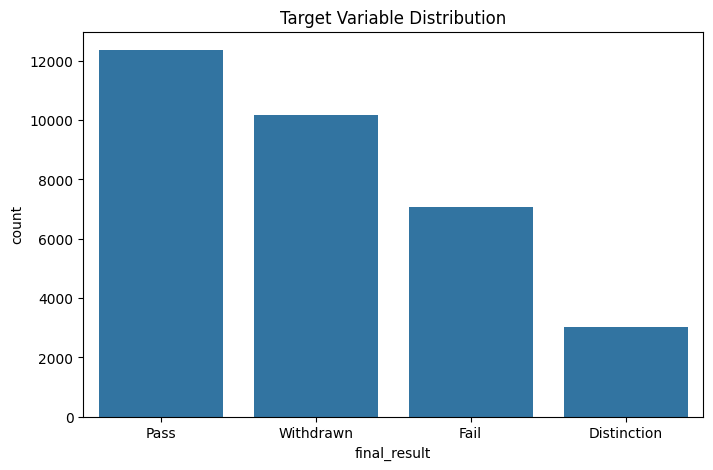

In [89]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=student_features,
    x="final_result"
)

plt.title("Target Variable Distribution")

plt.show()

In [90]:
selected_features = ["studied_credits","total_clicks","active_days","avg_daily_clicks","engagement_span_days","activity_density","click_std","daily_click_mean","click_cv","unique_sites_visited","clicks_early","clicks_mid","clicks_late","early_engagement_ratio"
]

In [91]:
X = student_features[selected_features]

In [92]:
y = student_features["final_result"]

In [93]:
label_encoder=LabelEncoder()
y_encoded=label_encoder.fit_transform(y)

In [94]:
dict(
    zip(
        label_encoder.classes_,    # this is used for checking the encoding
        range(
            len(label_encoder.classes_)
        )
    )
)

{'Distinction': 0, 'Fail': 1, 'Pass': 2, 'Withdrawn': 3}

In [95]:
X_train,X_test,y_train,y_test=train_test_split(
    X,y_encoded,test_size=0.2,random_state=42,stratify=y_encoded
)

In [96]:
#now feature scaling


In [97]:
X = X.replace(
    [np.inf, -np.inf],
    np.nan
)

X = X.fillna(0)

In [102]:
scaler=StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

The problem is there are values inf which we need to get rid of

In [ ]:
np.isinf(X).sum()

studied_credits           0
total_clicks              0
active_days               0
avg_daily_clicks          0
engagement_span_days      0
activity_density          0
click_std                 0
daily_click_mean          0
click_cv                  0
unique_sites_visited      0
clicks_early              0
clicks_mid                0
clicks_late               0
early_engagement_ratio    0
dtype: int64

In [ ]:
np.isinf(X).sum(axis=0)

studied_credits           0
total_clicks              0
active_days               0
avg_daily_clicks          0
engagement_span_days      0
activity_density          0
click_std                 0
daily_click_mean          0
click_cv                  0
unique_sites_visited      0
clicks_early              0
clicks_mid                0
clicks_late               0
early_engagement_ratio    0
dtype: int64

In [104]:
logistic_model=LogisticRegression(max_iter=1000)

In [105]:
logistic_model.fit(X_train_scaled,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [99]:
print(np.isinf(X_train).sum())

studied_credits             0
total_clicks                0
active_days                 0
avg_daily_clicks            0
engagement_span_days        0
activity_density          501
click_std                   0
daily_click_mean            0
click_cv                    0
unique_sites_visited        0
clicks_early                0
clicks_mid                  0
clicks_late                 0
early_engagement_ratio      0
dtype: int64


In [100]:
X_train = X_train.replace([np.inf, -np.inf], 0)
X_test = X_test.replace([np.inf, -np.inf], 0)

X_train = X_train.fillna(0)
X_test = X_test.fillna(0)

In [101]:
print(np.isinf(X_train).sum().sum())
print(X_train.isnull().sum().sum())

0
0


In [106]:
y_pred_logistic=logistic_model.predict(X_test_scaled)

Evaluation of the logistic regression model

In [107]:
accuracy_score(
    y_test,
    y_pred_logistic
)

0.66344531369842

In [108]:
print(
    classification_report(
        y_test,
        y_pred_logistic
    )
)

              precision    recall  f1-score   support

           0       0.48      0.02      0.04       605
           1       0.56      0.26      0.35      1411
           2       0.65      0.96      0.78      2472
           3       0.72      0.78      0.75      2031

    accuracy                           0.66      6519
   macro avg       0.60      0.50      0.48      6519
weighted avg       0.64      0.66      0.61      6519



In [109]:
conf_matrix = confusion_matrix(
    y_test,
    y_pred_logistic
)

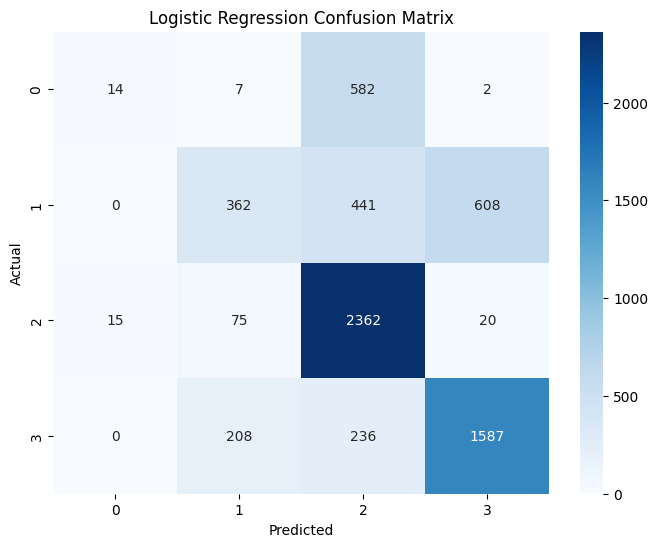

In [110]:
plt.figure(figsize=(8,6))

sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

We next move to RandomForestRegressor

In [111]:
random_forest_model=RandomForestClassifier(n_estimators=200,random_state=42)

In [113]:
random_forest_model.fit(X_train,y_train)  # cause RandomForest does not require scaling

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [114]:
y_pred_rf=random_forest_model.predict(X_test)

In [115]:
accuracy_score(
    y_test,
    y_pred_rf
)

0.6424298205246204